In [1]:
!pip -q install openpyxl

import pandas as pd

df = pd.read_excel(
    "/content/Muskoka_Area_Intensive_Sentinel lakes_Temperature_and_dissolved_oxygen_1976-2021- Revised and Raw Data.xlsx",
    engine="openpyxl"
)

display(df.head())


,LAKE,DISTRICT,TOWNSHIP,LATITUDE,LONGITUDE,DATE,YEAR,MONTH,SEASON,DEPTH,TEMPERATURE,DISSOLVED OXYGEN,STATION
0,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,0.1,0.90,NaN,3007754001
1,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,1.0,2.40,NaN,3007754001
2,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,2.0,3.00,NaN,3007754001
3,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,3.0,3.75,NaN,3007754001
4,BLUE CHALK LAKE,Muskoka Dist.,Ridout,451156,785631,1976-02-18,1976,2,Winter,4.0,3.80,NaN,3007754001


In [2]:
df.shape

(104319, 13)

In [3]:
df.isnull().sum()



,0
LAKE,0
DISTRICT,0
TOWNSHIP,0
LATITUDE,0
LONGITUDE,0
DATE,0
YEAR,0
MONTH,0
SEASON,0
DEPTH,0


In [4]:
blank_percentage = (df.isnull().sum() / len(df)) * 100

print('Percent of missing variables:',blank_percentage.round(2))


Percent of missing variables: LAKE                 0.00
DISTRICT             0.00
TOWNSHIP             0.00
LATITUDE             0.00
LONGITUDE            0.00
DATE                 0.00
YEAR                 0.00
MONTH                0.00
SEASON               0.00
DEPTH                0.00
TEMPERATURE          2.77
DISSOLVED OXYGEN    25.65
STATION              0.00
dtype: float64


In [5]:
df[["DEPTH", "TEMPERATURE", "DISSOLVED OXYGEN"]].describe()

,DEPTH,TEMPERATURE,DISSOLVED OXYGEN
count,104319.000000,101430.000000,77556.000000
mean,11.564774,8.514137,7.049976
std,8.684943,5.915419,3.239833
min,0.000000,0.000000,0.000000
25%,4.500000,4.500000,5.070000
50%,10.000000,5.630000,7.890000
75%,17.000000,10.800000,9.300000
max,37.000000,28.700000,17.000000


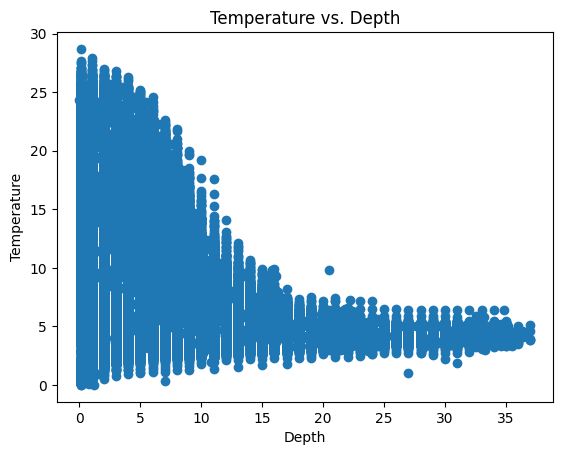

In [6]:
import matplotlib.pyplot as plt
temperature_depth = df.dropna(subset=['TEMPERATURE', 'DEPTH'])

plt.scatter(temperature_depth['DEPTH'], temperature_depth['TEMPERATURE'])
plt.xlabel('Depth')
plt.ylabel('Temperature')
plt.title('Temperature vs. Depth')
plt.show()


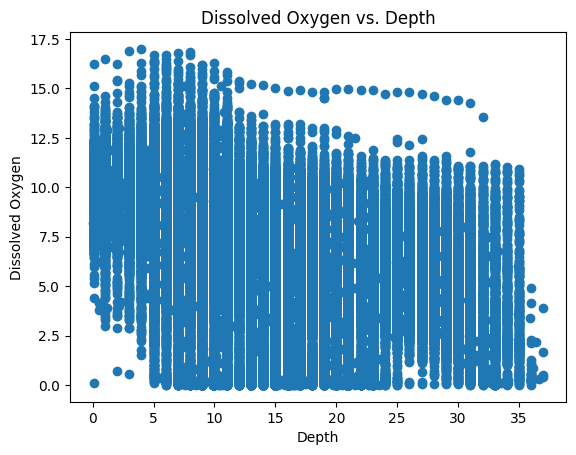

In [7]:
depth_dissolved_oxygen = df.dropna(subset=['DISSOLVED OXYGEN', 'DEPTH'])
plt.scatter(depth_dissolved_oxygen['DEPTH'], depth_dissolved_oxygen['DISSOLVED OXYGEN'])
plt.xlabel('Depth')
plt.ylabel('Dissolved Oxygen')
plt.title('Dissolved Oxygen vs. Depth')
plt.show()


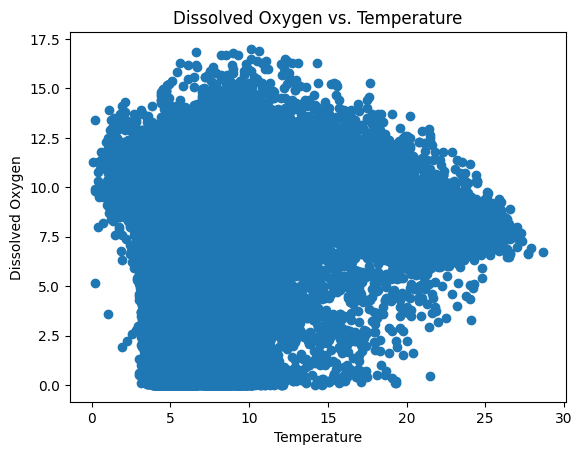

In [8]:
temperature_dissolved_oxygen = df.dropna(subset=['DISSOLVED OXYGEN', 'TEMPERATURE'])
plt.scatter(temperature_dissolved_oxygen['TEMPERATURE'], temperature_dissolved_oxygen['DISSOLVED OXYGEN'])
plt.xlabel('Temperature')
plt.ylabel('Dissolved Oxygen')
plt.title('Dissolved Oxygen vs. Temperature')
plt.show()


In [9]:
#correlation matrix that shows all the correlation between selected variables but in a table
correlation_matrix = df[['TEMPERATURE', 'DISSOLVED OXYGEN', 'DEPTH']].corr()

print(correlation_matrix)

                  TEMPERATURE  DISSOLVED OXYGEN     DEPTH
TEMPERATURE          1.000000          0.255888 -0.594653
DISSOLVED OXYGEN     0.255888          1.000000 -0.468555
DEPTH               -0.594653         -0.468555  1.000000


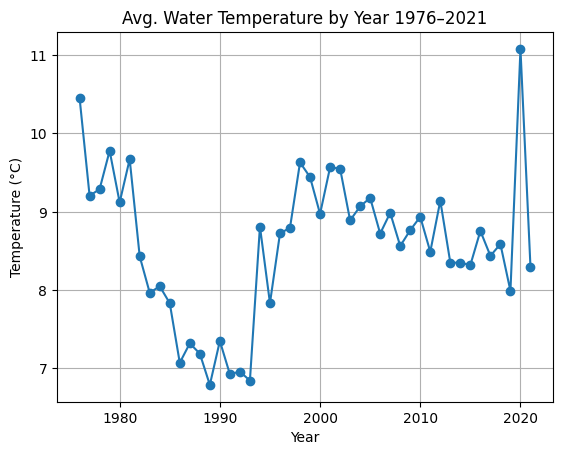

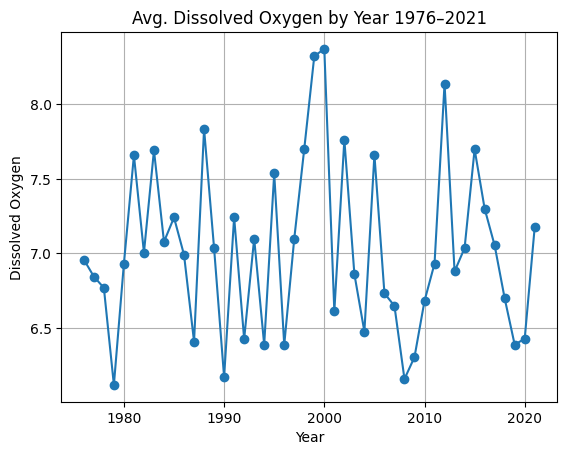

In [10]:
import matplotlib.pyplot as plt

# annual averages
avg_yearly_trends = df.groupby('YEAR')[['TEMPERATURE', 'DISSOLVED OXYGEN']].mean()

plt.plot(avg_yearly_trends.index, avg_yearly_trends['TEMPERATURE'], marker='o')
plt.title('Avg. Water Temperature by Year 1976–2021')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

plt.plot(avg_yearly_trends.index, avg_yearly_trends['DISSOLVED OXYGEN'], marker='o')
plt.title('Avg. Dissolved Oxygen by Year 1976–2021')
plt.xlabel('Year')
plt.ylabel('Dissolved Oxygen')
plt.grid(True)
plt.show()

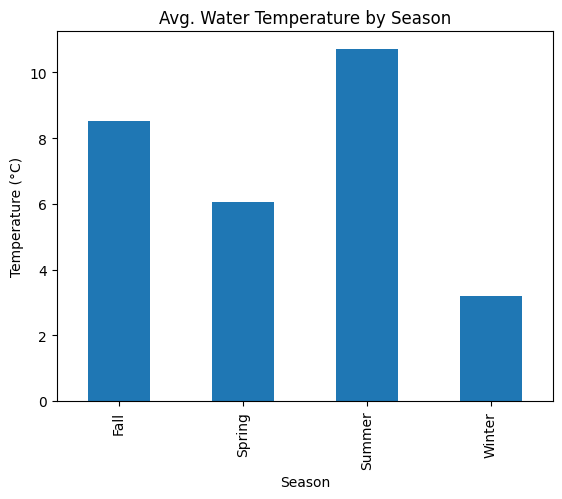

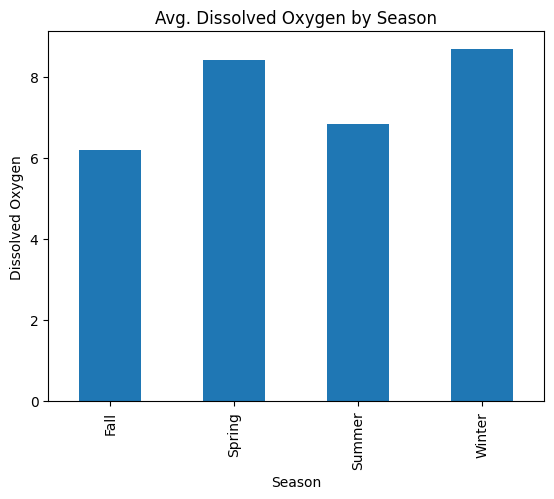

In [11]:
# avg analysis by season
avg_seasonal_trends = df.groupby('SEASON')[['TEMPERATURE', 'DISSOLVED OXYGEN']].mean()

avg_seasonal_trends['TEMPERATURE'].plot(kind='bar')
plt.title('Avg. Water Temperature by Season')
plt.xlabel('Season')
plt.ylabel('Temperature (°C)')
plt.show()

avg_seasonal_trends['DISSOLVED OXYGEN'].plot(kind='bar')
plt.title('Avg. Dissolved Oxygen by Season')
plt.xlabel('Season')
plt.ylabel('Dissolved Oxygen')
plt.show()

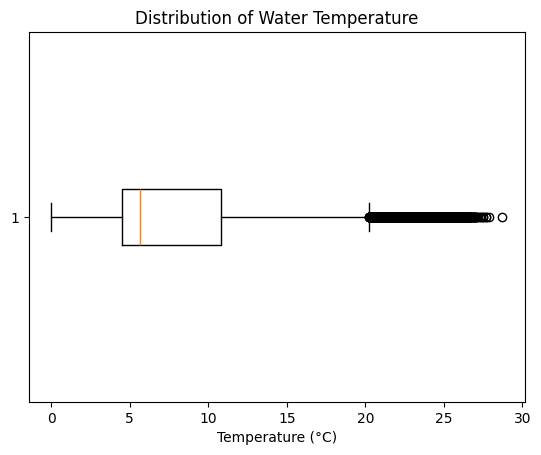

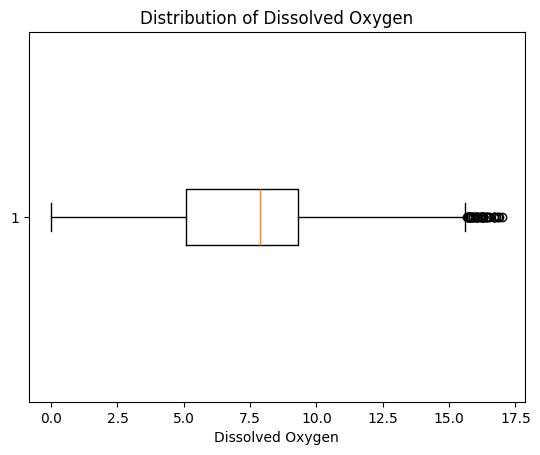

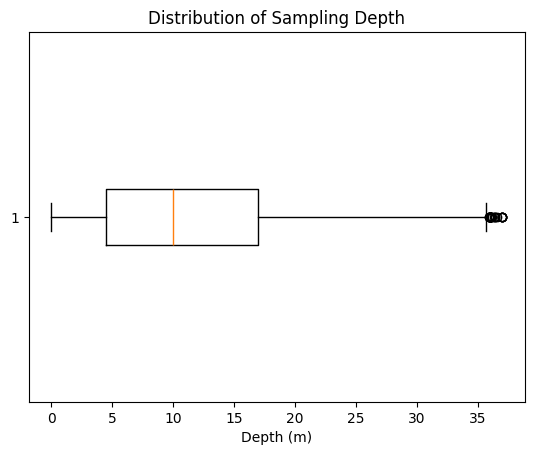

In [12]:
#boxplot to find outliers


plt.boxplot(df['TEMPERATURE'].dropna(), vert=False)
plt.xlabel('Temperature (°C)')
plt.title('Distribution of Water Temperature')
plt.show()

plt.boxplot(df['DISSOLVED OXYGEN'].dropna(), vert=False)
plt.xlabel('Dissolved Oxygen')
plt.title('Distribution of Dissolved Oxygen')
plt.show()

plt.boxplot(df['DEPTH'].dropna(), vert=False)
plt.xlabel('Depth (m)')
plt.title('Distribution of Sampling Depth')
plt.show()

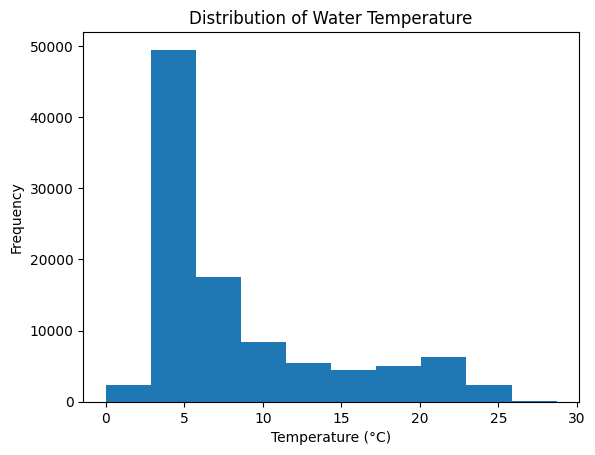

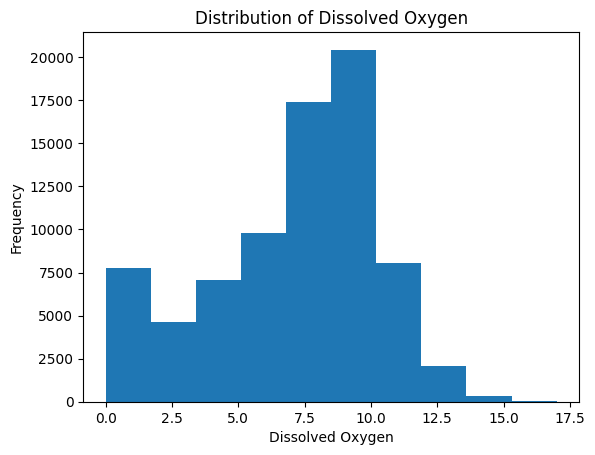

In [13]:
plt.hist(df['TEMPERATURE'].dropna())
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.title('Distribution of Water Temperature')
plt.show()

plt.hist(df['DISSOLVED OXYGEN'].dropna())
plt.xlabel('Dissolved Oxygen')
plt.ylabel('Frequency')
plt.title('Distribution of Dissolved Oxygen')
plt.show()

In [14]:
print(df['LAKE'].unique())
print(df['SEASON'].unique())

['BLUE CHALK LAKE' 'CHUB LAKE' 'CROSSON LAKE' 'DICKIE LAKE' 'HARP LAKE'
 'HENEY LAKE' 'PLASTIC LAKE' 'RED CHALK LAKE - EAST'
 'RED CHALK LAKE - MAIN']
['Winter' 'Spring' 'Summer' 'Fall']


In [15]:
model_df = df[
    ['DISSOLVED OXYGEN', 'TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE', 'SEASON']
].dropna()

print("Original rows:", len(df))
print("Rows available for modeling:", len(model_df))
print("Rows removed:", len(df) - len(model_df))

Original rows: 104319
Rows available for modeling: 76023
Rows removed: 28296


In [16]:
print(model_df['YEAR'].value_counts().sort_index())

YEAR
1976     209
1977    1977
1978    2002
1979    2267
1980    2244
1981    2445
1982    1446
1983    2390
1984    2289
1985    1989
1986    1837
1987    2046
1988    1986
1989    1784
1990    1814
1991    1810
1992    1275
1993    1116
1994     774
1995     911
1996     779
1997     760
1998    1550
1999    1729
2000    1793
2001    1565
2002    1704
2003    1860
2004    1890
2005    1778
2006    1785
2007    1843
2008    1765
2009    1915
2010    1989
2011    1835
2012    2042
2013    1741
2014    1753
2015    1613
2016    1711
2017    1816
2018    1465
2019    1408
2020     202
2021    1121
Name: count, dtype: int64


In [17]:
training_df = model_df[model_df['YEAR'] <= 2011].copy()
testing_df = model_df[model_df['YEAR'] >= 2012].copy()

print("Training rows:", len(training_df))
print("Testing rows:", len(testing_df))

Training rows: 61151
Testing rows: 14872


In [18]:
X_train = training_df[['TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE', 'SEASON']]
y_train = training_df['DISSOLVED OXYGEN']

X_test = testing_df[['TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE', 'SEASON']]
y_test = testing_df['DISSOLVED OXYGEN']

print("Training predictors:", X_train.shape)
print("Training target:", y_train.shape)
print("Testing predictors:", X_test.shape)
print("Testing target:", y_test.shape)

Training predictors: (61151, 5)
Training target: (61151,)
Testing predictors: (14872, 5)
Testing target: (14872,)


In [19]:
X_train_encoded = pd.get_dummies(X_train, columns=['LAKE', 'SEASON'], drop_first=True)

X_test_encoded = pd.get_dummies(X_test, columns=['LAKE', 'SEASON'], drop_first=True)

X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print(X_train_encoded.columns.tolist())
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

['TEMPERATURE', 'DEPTH', 'YEAR', 'LAKE_CHUB LAKE', 'LAKE_CROSSON LAKE', 'LAKE_DICKIE LAKE', 'LAKE_HARP LAKE', 'LAKE_HENEY LAKE', 'LAKE_PLASTIC LAKE', 'LAKE_RED CHALK LAKE - EAST', 'LAKE_RED CHALK LAKE - MAIN', 'SEASON_Spring', 'SEASON_Summer', 'SEASON_Winter']
Training shape: (61151, 14)
Testing shape: (14872, 14)


In [20]:
baseline_prediction = y_train.mean()

baseline_predictions = [baseline_prediction] * len(y_test)

print("Baseline prediction:", baseline_prediction)

Baseline prediction: 7.030662507563245


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Dissolved Oxygen MAE:", baseline_mae)
print("Baseline Dissolved Oxygen RMSE:", baseline_rmse)
print("Baseline Dissolved Oxygen R²:", baseline_r2)

Baseline Dissolved Oxygen MAE: 2.5972957184019094
Baseline Dissolved Oxygen RMSE: 3.210536133864065
Baseline Dissolved Oxygen R²: -0.0022070080796878777


In [22]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_encoded, y_train)

linear_predictions = linear_model.predict(X_test_encoded)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear regression MAE:", linear_mae)
print("Linear regression RMSE:", linear_rmse)
print("Linear regression R²:", linear_r2)

Linear regression MAE: 1.9460843511113795
Linear regression RMSE: 2.4697836603053442
Linear regression R²: 0.40691063422545815
